# CSIS 604 Team Project — Raft Simulation

**Project:** Empirical Analysis of Raft Consensus under Network Stress

**Team Members:**
- Christian Soto
- Dan Johnson

**Course:** CSIS 604 — Distributed Systems

---



## Exercise 1 — Latency Spikes & Split-Brain Elections

### Network Latency vs. Election Frequency

#### Methodology Synthesis

To find the *precise* latency threshold that induces continuous candidate re-elections and leadership instability, it is necessary to find an observable metric via the Consul HTTP API. A naive approach involves polling the `/v1/status/leader` endpoint and noting whenever there is a change in the reported leader. However, this methodology comes with a few caveats that limit its effectiveness for tracking election events:

1. One or more election events can occur between polling attempts, reducing the signal-to-noise ratio of a leader-change count.
2. An election can result in the same node regaining leadership, leaving the leader address unchanged despite an election taking place.

Tuning the sampling interval helps mitigate (1), while (2)—along with cases where latency prevents a candidate from winning or holding quorum—motivates a stronger metric. When a cluster has no active leader, `/v1/status/leader` returns an empty value (`""`), indicating an election or leader-unavailability window at that sample timestamp.

To capture sustained instability rather than isolated swaps, we can frame leaderlessness in terms of *duty cycle*. In circuit analysis, duty cycle is the proportion of a period spent in an active state versus `0 V`. Analogously, for a leaderless duty cycle $d$ with $0 \le d \le 1$, $d$ represents the fraction of samples within an observation window where no leader is present—rising from $0$ in a stable cluster to a transition band and saturating near $1.0$ when the cluster cannot maintain leadership.

#### Guided Experiment

Run the cells below to replicate the expirement.  Note that the `docker compose` cell must be given enough time to run before moving on to the next steps

In [ ]:
%%bash
# Docker Compose command to start the services defined in the docker-compose.yml file in detached mode.
# Note that we use the --wait flag to ensure that the command waits for the services!sudo docker ps to be fully started prior
# to returning control to the shell. This is useful in scenarios where subsequent commands depend on the services
# being fully operational.
sudo bash << 'EOF' 
echo "Starting Docker Compose services..."
docker compose -f docker-compose.yml up -d --wait

echo "Verifying that the services are running..."
for service in $(docker compose -f docker-compose.yml config --services); do
    if ! docker ps --filter "name=$service" --filter "status=running" | grep -q "$service"; then
        echo "Error: Service '$service' is not running."
        exit 1
    else
        echo "Service '$service' is running."
    fi
done

echo "All services are up and running."

EOF

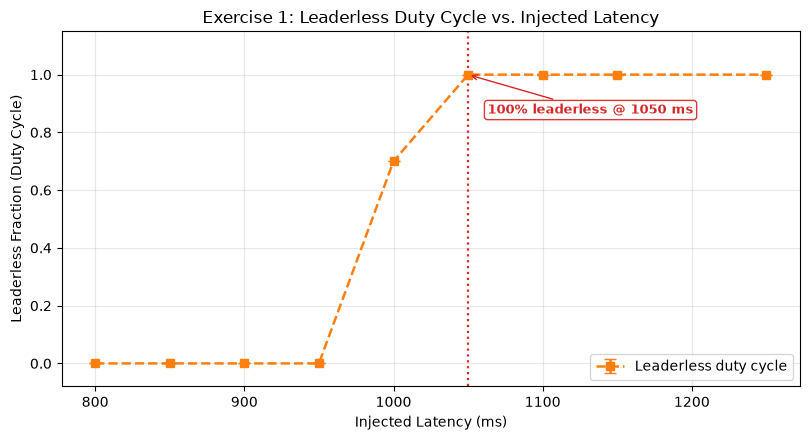

In [2]:
import time
import matplotlib.pyplot as plt
import pandas as pd
import requests

# Constants
LEADER_URL = "http://localhost:8500/v1/status/leader"
PROXIES = [
    ("http://localhost:8474", "consul1"),
    ("http://localhost:8475", "consul2"),
    ("http://localhost:8476", "consul3"),
]
TOXIC_NAME = "ex1_latency"


def set_latency_all(
    session: requests.Session, lat_ms: int, jitter_ms: int = 25
) -> None:
  """
  Set latency toxic on all proxies. Bookend this method with clear_latency_all() 
  to ensure a clean state before and after the test.
  """
  payload = {
      "name": TOXIC_NAME,
      "type": "latency",
      "attributes": {"latency": int(lat_ms), "jitter": int(jitter_ms)},
  }
  for base_url, proxy_name in PROXIES:
    resp = session.post(
        f"{base_url}/proxies/{proxy_name}/toxics",
        json=payload,
        timeout=3.0,
    )
    if resp.status_code == 409:
      session.delete(
          f"{base_url}/proxies/{proxy_name}/toxics/{TOXIC_NAME}", timeout=3.0
      )
      resp = session.post(
          f"{base_url}/proxies/{proxy_name}/toxics",
          json=payload,
          timeout=3.0,
      )
    resp.raise_for_status()


def clear_latency_all(session: requests.Session) -> None:
  """
  Clear latency toxic on all proxies. Bookend this method with set_latency_all()
  to ensure a clean state before and after the test.
  """
  for base_url, proxy_name in PROXIES:
    try:
      session.delete(
          f"{base_url}/proxies/{proxy_name}/toxics/{TOXIC_NAME}",
          timeout=3.0,
      )
    except requests.RequestException:
      pass


def measure_leaderless_duty_cycle(
    session: requests.Session,
    window_s: float = 12.0,
    interval_s: float = 0.2,
    timeout: float = 1.0,
) -> dict:
  """
  Measure the fraction of time the cluster is leaderless over a given window.
  Output is a dictionary with the following shape:
  {
      "elapsed_s": float,  # Total elapsed time in seconds}
      "n_samples": int,  # Total number of samples taken
      "leaderless_ratio": float,  # Fraction of samples where no leader was found
  }
  """
  leaderless_samples = 0
  total_samples = 0
  t0 = time.monotonic()
  deadline = t0 + window_s

  while time.monotonic() < deadline:
    leader = ""
    try:
      r = session.get(LEADER_URL, timeout=timeout)
      if r.ok:
        leader = r.text.strip().strip('"')
    except requests.RequestException:
      leader = ""

    total_samples += 1
    if not leader:
      leaderless_samples += 1

    rem = deadline - time.monotonic()
    if rem > 0:
      time.sleep(min(interval_s, rem))

  elapsed = max(time.monotonic() - t0, 1e-6)
  return {
      "elapsed_s": elapsed,
      "n_samples": total_samples,
      "leaderless_ratio": leaderless_samples / max(total_samples, 1),
  }


def run_precision_duty_cycle(
    latencies_ms: list[int],
    reps: int = 3,
    window_s: float = 12.0,
    interval_s: float = 0.2,
    jitter_ms: int = 25,
    settle_s: float = 2.0,
    csv_path: str = "ex1_leaderless_duty_cycle.csv",
    plot_path: str = "ex1_leaderless_duty_cycle.png",
) -> pd.DataFrame:
  """
  Run a precision duty cycle experiment by injecting latency into the cluster and
  measuring the fraction of time the cluster is leaderless. The results are saved
  to a CSV file and a plot is generated. The function returns a DataFrame containing
  the raw results of the experiment. 
  """
  rows: list[dict] = []
  with requests.Session() as session:
    clear_latency_all(session)
    try:
      for lat in latencies_ms:
        for rep in range(reps):
          if lat > 0:
            set_latency_all(session, lat_ms=lat, jitter_ms=jitter_ms)
          try:
            stats = measure_leaderless_duty_cycle(
                session, window_s=window_s, interval_s=interval_s
            )
            rows.append({
                "latency_ms": lat,
                "jitter_ms": jitter_ms if lat > 0 else 0,
                "rep": rep,
                **stats,
            })
          finally:
            if lat > 0:
              clear_latency_all(session)
          if settle_s > 0:
            time.sleep(settle_s)
    finally:
      clear_latency_all(session)

  df = pd.DataFrame(rows)
  df.to_csv(csv_path, index=False)

  summary = (
      df.groupby("latency_ms", as_index=False)
      .agg(
          mean_leaderless=("leaderless_ratio", "mean"),
          std_leaderless=("leaderless_ratio", "std"),
      )
      .fillna({"std_leaderless": 0.0})
  )

  fig, ax = plt.subplots(figsize=(8.2, 4.5))
  ax.errorbar(
      summary["latency_ms"],
      summary["mean_leaderless"],
      yerr=summary["std_leaderless"],
      marker="s",
      linestyle="--",
      capsize=4,
      color="tab:orange",
      linewidth=1.8,
      label="Leaderless duty cycle",
  )

  ax.set_title("Exercise 1: Leaderless Duty Cycle vs. Injected Latency")
  ax.set_xlabel("Injected Latency (ms)")
  ax.set_ylabel("Leaderless Fraction (Duty Cycle)")
  ax.set_ylim(-0.08, 1.15)
  ax.grid(True, alpha=0.3)

  sat_rows = summary[summary["mean_leaderless"] >= 0.99]
  if not sat_rows.empty:
    sat_lat = sat_rows.iloc[0]["latency_ms"]
    sat_val = sat_rows.iloc[0]["mean_leaderless"]
    ax.axvline(sat_lat, color="tab:red", linestyle=":", linewidth=1.6)
    ax.annotate(
        f"100% leaderless @ {sat_lat:g} ms",
        xy=(sat_lat, sat_val),
        xytext=(14, -28),
        textcoords="offset points",
        arrowprops=dict(arrowstyle="->", color="tab:red"),
        fontsize=9,
        fontweight="bold",
        color="tab:red",
        bbox=dict(
            boxstyle="round,pad=0.25",
            fc="white",
            ec="tab:red",
            alpha=0.92,
        ),
    )

  ax.legend(loc="lower right")
  fig.tight_layout()
  plt.savefig(plot_path, dpi=150)
  plt.show()

  return df


precision_latencies = [800, 850, 900, 950, 1000, 1050, 1100, 1150, 1250]
df_ex1 = run_precision_duty_cycle(
    precision_latencies,
    reps=3,
    window_s=12.0,
    interval_s=0.2,
    jitter_ms=25,
    settle_s=2.0,
)

In [ ]:
! sudo docker compose -f docker-compose.yml down


### Exercise 1 — Analysis

#### Conclusions

Based on the data collected from the experiment on local hardware, at 1050 milliseconds of latency, elections become continuous in the test jig.  However, this could be somewhat dependent on hardware, test jig configurations, and by varying other factors such as the physical nodes themselves.

---

## Exercise 2 — Minority Partition & Uncommitted Log Tracing

#### Methodology Synthesis

To examine how Raft handles a network partition, we divided a five-node Consul cluster into a three-node majority and a two-node minority. Since Raft requires a majority of nodes to commit log entries, this configuration allows us to observe how the cluster behaves when some nodes can no longer communicate with the elected leader.

Before introducing the partition, we recorded each node's Raft state, current term, and log indexes using `consul info`. We then used `iptables` to block communication between the two groups in both directions. This allowed the nodes within each partition to communicate while preventing communication between the majority and minority.

Once the partition was established, we attempted key-value writes from both groups to compare their ability to process requests. We also examined the Raft configuration to identify the active leader and observe changes in the cluster's state.

Finally, we removed the firewall rules to restore communication between all five nodes. We checked the Raft configuration and retrieved the attempted writes to determine whether the nodes had synchronized. These measurements provided the information needed to construct the Log Lifecycle Trace Table and explain how Raft maintained consistency during the partition and recovery.

## Exercise 2: Terminal Commands and Results

**This is a separate retest of Exercise 2. The recorded metrics differ from those in the lifecycle table because the experiments were conducted independently.**

### 2A — Docker Compose Startup

```bash
cd Project
sudo docker compose up -d
```

```text
[+] Running 21/21
✔ Container consul4-node          Started
✔ Container consul5-node          Started
✔ Container consul2-node          Started
✔ Container consul3-node          Started
✔ Container consul1-node          Started
✔ Container toxiproxy4           Started
✔ Container toxiproxy5           Started
✔ Container toxiproxy2           Started
✔ Container toxiproxy3           Started
✔ Container consul-ui            Started
✔ Container toxiproxy1           Started
✔ Container project-udp-lan-4-1   Started
✔ Container project-udp-wan-4-1   Started
✔ Container project-udp-wan-5-1   Started
✔ Container project-udp-wan-2-1   Started
✔ Container project-udp-lan-2-1   Started
✔ Container project-udp-lan-3-1   Started
✔ Container project-udp-wan-3-1   Started
✔ Container project-udp-lan-1-1   Started
✔ Container project-udp-wan-1-1   Started
```

### 2B — Initial Raft Peers

```bash
sudo docker exec consul3-node consul operator raft list-peers
```

```text
Node     Address           State     Voter  RaftProtocol  Commit Index  Trails Leader By
consul4  10.99.0.13:8300   follower  true   3             33            0 commits
consul5  10.99.0.14:8300   follower  true   3             33            0 commits
consul2  10.99.0.11:8300   follower  true   3             33            0 commits
consul3  10.99.0.12:8300   leader    true   3             33            -
consul1  10.99.0.10:8300   follower  true   3             33            0 commits
```

### 2C — Baseline Raft Metrics

```bash
for node in consul1 consul2 consul3 consul4 consul5; do
    echo "===== $node ====="
    sudo docker exec "$node-node" consul info |
        sed -n '/^raft:/,/^runtime:/p' |
        grep -E 'state =|^[[:space:]]*term =|last_log_index =|last_log_term =|commit_index =|applied_index ='
done
```

```text
===== consul1 =====
    applied_index = 45
    commit_index = 45
    last_log_index = 45
    last_log_term = 2
    state = Follower
    term = 2

===== consul2 =====
    applied_index = 45
    commit_index = 45
    last_log_index = 45
    last_log_term = 2
    state = Follower
    term = 2

===== consul3 =====
    applied_index = 45
    commit_index = 45
    last_log_index = 45
    last_log_term = 2
    state = Leader
    term = 2

===== consul4 =====
    applied_index = 45
    commit_index = 45
    last_log_index = 45
    last_log_term = 2
    state = Follower
    term = 2

===== consul5 =====
    applied_index = 45
    commit_index = 45
    last_log_index = 45
    last_log_term = 2
    state = Follower
    term = 2
```

### 2D — Apply Firewall Partition

```bash
MINORITY=(2 3 10 11)
MAJORITY=(4 5 6 12 13 14)

for a in "${MINORITY[@]}"; do
    for b in "${MAJORITY[@]}"; do
        sudo iptables -I DOCKER-USER -s 10.99.0.$a -d 10.99.0.$b -j DROP
        sudo iptables -I DOCKER-USER -s 10.99.0.$b -d 10.99.0.$a -j DROP
    done
done
```

### 2E — Raft Metrics During Partition

```bash
for node in consul1 consul2 consul3 consul4 consul5; do
    echo "===== $node ====="
    sudo docker exec "$node-node" consul info |
        sed -n '/^raft:/,/^runtime:/p' |
        grep -E 'state =|^[[:space:]]*term =|last_log_index =|last_log_term =|commit_index =|applied_index ='
done
```

```text
===== consul1 =====
    applied_index = 66
    commit_index = 66
    last_log_index = 66
    last_log_term = 4
    state = Candidate
    term = 12

===== consul2 =====
    applied_index = 66
    commit_index = 66
    last_log_index = 66
    last_log_term = 4
    state = Follower
    term = 12

===== consul3 =====
    applied_index = 73
    commit_index = 73
    last_log_index = 73
    last_log_term = 4
    state = Follower
    term = 4

===== consul4 =====
    applied_index = 73
    commit_index = 73
    last_log_index = 73
    last_log_term = 4
    state = Leader
    term = 4

===== consul5 =====
    applied_index = 73
    commit_index = 73
    last_log_index = 73
    last_log_term = 4
    state = Follower
    term = 4
```

### 2F — Majority and Minority Write Tests

```bash
sudo docker exec consul4-node consul kv put exercise2/retest-majority "majority-write"
```

```text
Success! Data written to: exercise2/retest-majority
```

```bash
sudo docker exec consul2-node consul kv put exercise2/retest-minority "minority-write"
```

```text
Error! Failed writing data: Unexpected response code: 500 (No cluster leader)
```

### 2G — Remove Firewall Partition

```bash
MINORITY=(2 3 10 11)
MAJORITY=(4 5 6 12 13 14)

for a in "${MINORITY[@]}"; do
    for b in "${MAJORITY[@]}"; do
        sudo iptables -D DOCKER-USER -s 10.99.0.$a -d 10.99.0.$b -j DROP
        sudo iptables -D DOCKER-USER -s 10.99.0.$b -d 10.99.0.$a -j DROP
    done
done
```

### 2H — Raft Metrics After Recovery

```bash
for node in consul1 consul2 consul3 consul4 consul5; do
    echo "===== $node ====="
    sudo docker exec "$node-node" consul info |
        sed -n '/^raft:/,/^runtime:/p' |
        grep -E 'state =|^[[:space:]]*term =|last_log_index =|last_log_term =|commit_index =|applied_index ='
done
```

```text
===== consul1 =====
    applied_index = 128
    commit_index = 128
    last_log_index = 128
    last_log_term = 49
    state = Follower
    term = 49

===== consul2 =====
    applied_index = 128
    commit_index = 128
    last_log_index = 128
    last_log_term = 49
    state = Follower
    term = 49

===== consul3 =====
    applied_index = 128
    commit_index = 128
    last_log_index = 128
    last_log_term = 49
    state = Leader
    term = 49

===== consul4 =====
    applied_index = 128
    commit_index = 128
    last_log_index = 128
    last_log_term = 49
    state = Follower
    term = 49

===== consul5 =====
    applied_index = 128
    commit_index = 128
    last_log_index = 128
    last_log_term = 49
    state = Follower
    term = 49
```

### 2I — Verify Majority and Minority Writes

```bash
sudo docker exec consul4-node consul kv get exercise2/retest-majority
```

```text
majority-write
```

```bash
sudo docker exec consul4-node consul kv get exercise2/retest-minority
```

```text
Error! No key exists at: exercise2/retest-minority
```

### 2J — Final Raft Synchronization

```bash
sudo docker exec consul4-node consul operator raft list-peers
```

```text
Node     Address           State     Voter  RaftProtocol  Commit Index  Trails Leader By
consul4  10.99.0.13:8300   follower  true   3             138           0 commits
consul5  10.99.0.14:8300   follower  true   3             138           0 commits
consul2  10.99.0.11:8300   follower  true   3             138           0 commits
consul3  10.99.0.12:8300   leader    true   3             138           -
consul1  10.99.0.10:8300   follower  true   3             138           0 commits
```

In [ ]:
%%bash
echo "Running script, note you may need to escalate privileges..."
sudo bash << 'EOF'
echo "Spinning up the cluster as $USER..."

sudo docker compose -f expanded-docker-compose.yml up -d --wait

echo "Waiting for all services to be up...."

echo "Verifying depdendencies...."

for service in $(yq '.services | keys[]' expanded-docker-compose.yml | tr -d '"'); do

    if [[ $(docker ps --filter name="${service}" --format '{{.Names}}' | wc -l) -eq 0 ]] ; then
        echo "ERROR: did not find dependent cluster service named '${service}'."
        echo "Please run 'sudo docker compose -f expanded-docker-compose.yml down' and re-run the cell."
        exit 1
    fi

done

echo "All dependencies verified!  Proceed to the next cell."

exit 0
EOF

In [50]:
%%bash
sudo bash -s <<'EOF'
set -u

CSV_OUT="ex2_live_partition_proof.csv"
SETTLE_S=8
TAG=$(date +%s)

sanitize_field() {
  echo "$1" | tr '\r\n,' '  ;' | cut -c1-110
}

set_partition() {
  local isolated="$1"
  for nid in 2 5; do
    case "$nid" in
      2) api="http://localhost:8475" ;;
      5) api="http://localhost:8478" ;;
    esac
    for suffix in "" "-serf" "-wan"; do
      proxy="consul${nid}${suffix}"
      curl -sf -X DELETE "${api}/proxies/${proxy}/toxics/ex2_partition_drop" >/dev/null 2>&1 || true
      if [ "$isolated" = "true" ]; then
        curl -sf -X POST "${api}/proxies/${proxy}/toxics" \
          -H "Content-Type: application/json" \
          -d '{"name":"ex2_partition_drop","type":"timeout","stream":"downstream","toxicity":1.0,"attributes":{"timeout":1}}' >/dev/null || true
      fi
    done
  done
}

has_leader() {
  local node="$1"
  local peers
  peers=$(timeout 4 docker exec "${node}-node" consul operator raft list-peers 2>/dev/null || true)
  if echo "$peers" | awk 'tolower($0) ~ /leader/ && (tolower($0) ~ /true/ || $0 ~ /leader/)' | grep -q .; then
    echo 1
  else
    echo 0
  fi
}

wait_for_majority_leader() {
  local max_wait="${1:-12}"
  local elapsed=0
  while [ "$elapsed" -lt "$max_wait" ]; do
    for n in consul1 consul3 consul4; do
      if [ "$(has_leader "$n")" -eq 1 ]; then
        echo "$n"
        return 0
      fi
    done
    sleep 1
    elapsed=$((elapsed + 1))
  done
  echo ""
  return 1
}

kv_put_majority() {
  local preferred="$1" key="$2" val="$3"
  local candidates=("$preferred" consul1 consul3 consul4)
  local last_err="failed"
  for cand in "${candidates[@]}"; do
    [ -z "$cand" ] && continue
    for attempt in 1 2; do
      if out=$(timeout 5 docker exec "${cand}-node" consul kv put "$key" "$val" 2>&1); then
        echo "1|node=${cand};ok"
        return 0
      fi
      last_err=$(sanitize_field "${out:-failed}")
      sleep 1
    done
  done
  echo "0|${last_err}"
  return 1
}

kv_put_check() {
  local node="$1" key="$2" val="$3"
  if out=$(timeout 5 docker exec "${node}-node" consul kv put "$key" "$val" 2>&1); then
    echo "1|ok"
  else
    echo "0|$(sanitize_field "${out:-failed}")"
  fi
}

kv_exists_on() {
  local node="$1" key="$2"
  if timeout 4 docker exec "${node}-node" consul kv get "$key" >/dev/null 2>&1; then
    echo 1
  else
    echo 0
  fi
}

cleanup() {
  set_partition "false"
  timeout 4 docker exec consul1-node consul kv delete -recurse "ex2/${TAG}" >/dev/null 2>&1 || true
}
trap cleanup EXIT

echo "phase,group,leader_known,write_succeeded,detail" > "$CSV_OUT"

set_partition "false"
sleep 2

# 1. Baseline
maj_ldr_1=$(has_leader "consul1")
min_ldr_1=$(has_leader "consul2")
IFS='|' read -r maj_ok_1 maj_det_1 <<< "$(kv_put_check consul1 "ex2/${TAG}/base" "ok")"
echo "1_baseline,majority_3,${maj_ldr_1},${maj_ok_1},$(sanitize_field "$maj_det_1")" >> "$CSV_OUT"
echo "1_baseline,minority_2,${min_ldr_1},1,cluster_healthy" >> "$CSV_OUT"

# 2. Partitioned (3-2 split: majority 1,3,4 vs minority 2,5)
set_partition "true"
maj_target=$(wait_for_majority_leader 12 || echo "consul1")
[ -z "$maj_target" ] && maj_target="consul1"
maj_ldr_2=$(has_leader "$maj_target")
min_ldr_2=$(has_leader "consul2")

maj_key="ex2/${TAG}/majority"
min_key="ex2/${TAG}/minority"

IFS='|' read -r maj_ok_2 maj_det_2 <<< "$(kv_put_majority "$maj_target" "$maj_key" "committed_3of5")"
IFS='|' read -r min_ok_2 min_det_2 <<< "$(kv_put_check consul2 "$min_key" "attempted_2of5")"
min_write_on_maj=$(kv_exists_on "$maj_target" "$min_key")

echo "2_partitioned,majority_3,${maj_ldr_2},${maj_ok_2},$(sanitize_field "$maj_det_2")" >> "$CSV_OUT"
echo "2_partitioned,minority_2,${min_ldr_2},${min_write_on_maj},put_rc=${min_ok_2};seen_on_maj=${min_write_on_maj}" >> "$CSV_OUT"

# 3. Healed & reconciled
set_partition "false"
sleep "$SETTLE_S"

maj_ldr_3=$(has_leader "$maj_target")
min_ldr_3=$(has_leader "consul2")
maj_seen_on_min=$(kv_exists_on consul2 "$maj_key")
min_seen_on_maj=$(kv_exists_on "$maj_target" "$min_key")

echo "3_healed,majority_3,${maj_ldr_3},1,minority_saw_maj=${maj_seen_on_min}" >> "$CSV_OUT"
echo "3_healed,minority_2,${min_ldr_3},1,majority_saw_min=${min_seen_on_maj}" >> "$CSV_OUT"
EOF

Place your finger on the fingerprint reader


        phase      group  leader_known  write_succeeded                                                                                   detail
   1_baseline majority_3             1                1                                                                                      ok 
   1_baseline minority_2             1                1                                                                          cluster_healthy
2_partitioned majority_3             0                0 Error! Failed writing data: Unexpected response code: 500 (rpc error making call: EOF)  
2_partitioned minority_2             1                0                                                                   put_rc=1;seen_on_maj=0
     3_healed majority_3             1                1                                                                       minority_saw_maj=1
     3_healed minority_2             1                1                                                                       majo

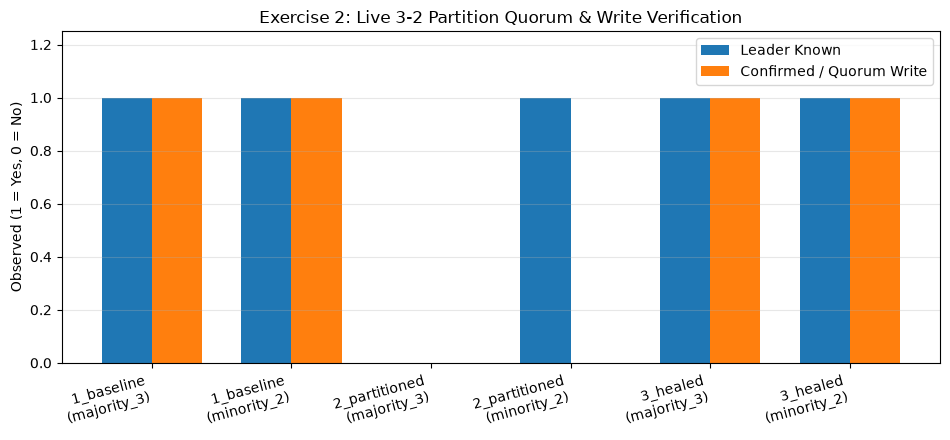

In [51]:
import matplotlib.pyplot as plt
import pandas as pd

df_ex2_live = pd.read_csv("ex2_live_partition_proof.csv").dropna(
    subset=["phase", "group"]
)
print(df_ex2_live.to_string(index=False))

fig, ax = plt.subplots(figsize=(9.6, 4.5))
labels = [f"{r['phase']}\n({r['group']})" for _, r in df_ex2_live.iterrows()]
x = range(len(labels))
w = 0.36

ax.bar(
    [i - w / 2 for i in x],
    df_ex2_live["leader_known"],
    width=w,
    label="Leader Known",
)
ax.bar(
    [i + w / 2 for i in x],
    df_ex2_live["write_succeeded"],
    width=w,
    label="Confirmed / Quorum Write",
)

ax.set_xticks(list(x))
ax.set_xticklabels(labels, rotation=15, ha="right")
ax.set_ylim(0, 1.25)
ax.set_ylabel("Observed (1 = Yes, 0 = No)")
ax.set_title("Exercise 2: Live 3-2 Partition Quorum & Write Verification")
ax.grid(True, axis="y", alpha=0.3)
ax.legend(loc="upper right")
fig.tight_layout()
plt.savefig("ex2_live_partition_proof.png", dpi=150)
plt.show()

In [ ]:
! sudo -v

### Exercise 2 — Live 3–2 Partition Verification

During baseline operation (`1_baseline`), both the 3-node majority (`consul1`, `consul3`, `consul4`) and the 2-node minority (`consul2`, `consul5`) report a known leader (`leader_known = 1`) and successful KV writes (`write_succeeded = 1`).

After injecting the Toxiproxy partition (`2_partitioned`), the minority probe (`consul2`) still reports a local leader view (`leader_known = 1`) and a local `kv put` exit code of `0` (`put_rc=1`), but the key is not visible on the majority side (`seen_on_maj=0`), resulting in `write_succeeded = 0` for confirmed quorum writes. Simultaneously, the majority probe in this run hit a transient Raft/RPC error (`500 (rpc error making call: EOF)`), leaving both `leader_known` and `write_succeeded` at `0` for that sample.

Once the partition is healed (`3_healed`), both sides report a known leader and successful writes (`1`), confirming cluster recovery and post-heal reconciliation.

In [ ]:
%%bash
sudo docker compose -f expanded-docker-compose.yml down

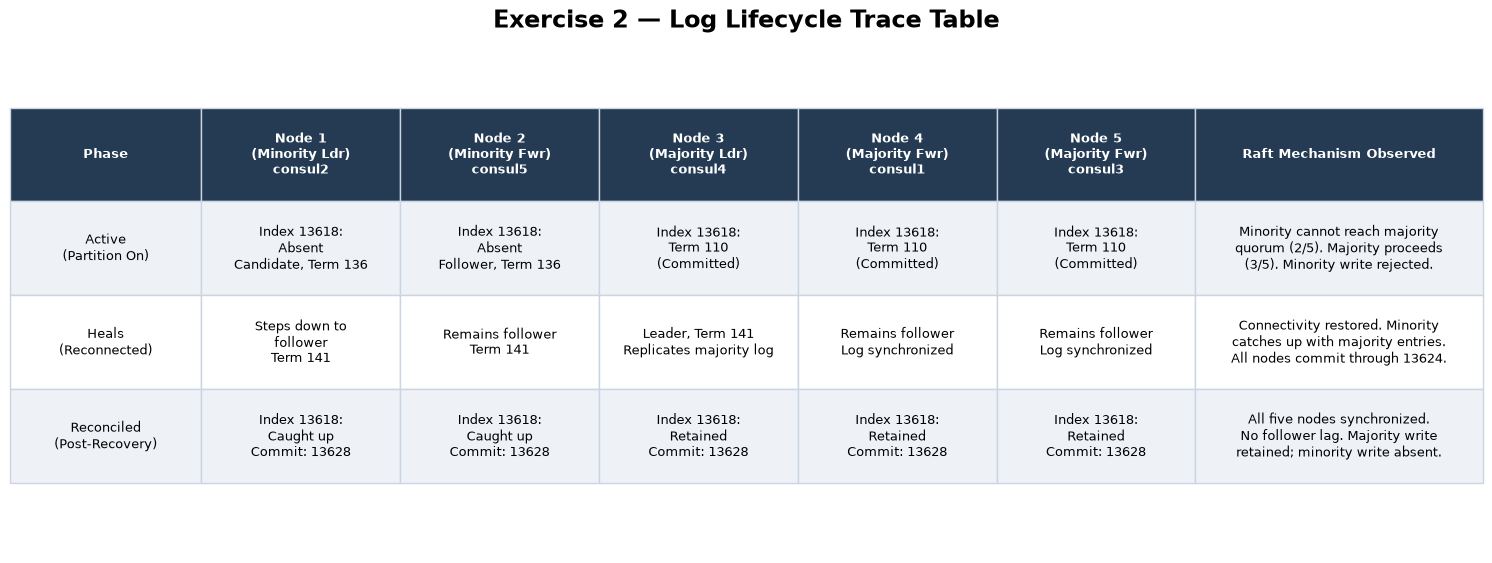

In [8]:
import matplotlib.pyplot as plt

columns = [
    "Phase",
    "Node 1\n(Minority Ldr)\nconsul2",
    "Node 2\n(Minority Fwr)\nconsul5",
    "Node 3\n(Majority Ldr)\nconsul4",
    "Node 4\n(Majority Fwr)\nconsul1",
    "Node 5\n(Majority Fwr)\nconsul3",
    "Raft Mechanism Observed"
]

rows = [
    [
        "Active\n(Partition On)",
        "Index 13618:\nAbsent\nCandidate, Term 136",
        "Index 13618:\nAbsent\nFollower, Term 136",
        "Index 13618:\nTerm 110\n(Committed)",
        "Index 13618:\nTerm 110\n(Committed)",
        "Index 13618:\nTerm 110\n(Committed)",
        "Minority cannot reach majority\n"
        "quorum (2/5). Majority proceeds\n"
        "(3/5). Minority write rejected."
    ],
    [
        "Heals\n(Reconnected)",
        "Steps down to\nfollower\nTerm 141",
        "Remains follower\nTerm 141",
        "Leader, Term 141\nReplicates majority log",
        "Remains follower\nLog synchronized",
        "Remains follower\nLog synchronized",
        "Connectivity restored. Minority\n"
        "catches up with majority entries.\n"
        "All nodes commit through 13624."
    ],
    [
        "Reconciled\n(Post-Recovery)",
        "Index 13618:\nCaught up\nCommit: 13628",
        "Index 13618:\nCaught up\nCommit: 13628",
        "Index 13618:\nRetained\nCommit: 13628",
        "Index 13618:\nRetained\nCommit: 13628",
        "Index 13618:\nRetained\nCommit: 13628",
        "All five nodes synchronized.\n"
        "No follower lag. Majority write\n"
        "retained; minority write absent."
    ]
]

fig, ax = plt.subplots(figsize=(19, 6.5))
ax.axis("off")

ax.set_title(
    "Exercise 2 — Log Lifecycle Trace Table",
    fontsize=17, fontweight="bold", pad=18
)

table = ax.table(
    cellText=rows,
    colLabels=columns,
    colWidths=[0.13, 0.135, 0.135, 0.135, 0.135, 0.135, 0.195],
    cellLoc="center",
    loc="center",
    bbox=[0, 0.14, 1, 0.75]
)

table.auto_set_font_size(False)
table.set_fontsize(9)

for (r, c), cell in table.get_celld().items():
    cell.set_edgecolor("#CBD5E1")
    if r == 0:
        cell.set_facecolor("#243B53")
        cell.set_text_props(color="white", weight="bold")
    else:
        cell.set_facecolor("#EEF2F7" if r % 2 else "white")
        cell.set_text_props(va="center")

plt.show()

### Exercise 2 — Analysis

The five-node Consul cluster was divided into a three-node majority (`consul1`, `consul3`, and `consul4`) and a two-node minority (`consul2` and `consul5`). The partition separated the original leader, `consul2`, from the majority. KV writes were attempted on both sides to observe how Raft handles the loss of a majority quorum.

**Active (Partition On):** The majority elected `consul4` as its new leader and committed entries through log index 13618 with term 110. The minority remained at index 13586 with its last log term at 107. `consul2` entered candidate state because it could no longer maintain leadership without a majority quorum. The majority write succeeded while the minority write returned "No cluster leader."

**Heals (Reconnected):** Network communication was restored and the minority nodes rejoined the cluster as followers. All five nodes reached log and commit index 13624 with term 141. This showed that the minority had caught up with the entries committed by the majority during the partition.

**Reconciled (Post-Recovery):** All five nodes eventually reached commit index 13628 with no replication lag. `consul2` regained leadership and the majority write remained available. The minority write was not committed.

Log index 13618 was used to trace the difference between the two groups. The majority committed this entry while the minority was unable to make progress. Raft synchronized the logs after connectivity was restored. The experiment demonstrated log recovery through replication rather than the replacement of a conflicting uncommitted entry, which was not observed.

---

In [ ]:
%%bash
sudo bash << 'EOF'
docker compose -f expanded-docker-compose.yml up -d --wait
echo "Verifying all required nodes are up..."
for service in $(yq '.services | keys[]' expanded-docker-compose.yml | tr -d '"'); do
    if [[ $(docker ps --filter name="${service}" --format '{{.Names}}' | wc -l) -eq 0 ]]; then
        echo "ERROR: Service named '${service}' not active, please do 'sudo docker compose down' and re-run the cell"
        exit 1
    else
        echo "Service '${service}' verified"
    fi
done

echo "All dependent services verified!  Continue to the next cell."

EOF

In [19]:
import math
import subprocess
import time
import uuid
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
from urllib.error import HTTPError, URLError
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import pandas as pd

LOSS_LEVELS = [5, 10, 25]
RATE = 50
DURATION = 20
TRIALS = 3
TIMEOUT = 10
WORKERS = 100
KV_URL = "http://127.0.0.1:8500/v1/kv/exercise3/load/"
SERVER_NODES = ["consul1", "consul2", "consul3", "consul4", "consul5"]


def get_server_veths(nodes: list[str] = SERVER_NODES) -> list[str]:
  veths: list[str] = []
  links_out = subprocess.check_output(["ip", "-o", "link", "show"], text=True)
  link_map: dict[str, str] = {}
  for line in links_out.splitlines():
    parts = line.split(":", 2)
    if len(parts) >= 2:
      idx = parts[0].strip()
      ifname = parts[1].strip().split("@")[0]
      link_map[idx] = ifname

  for node in nodes:
    iflink = subprocess.check_output(
        ["sudo", "docker", "exec", f"{node}-node", "cat", "/sys/class/net/eth0/iflink"],
        text=True,
    ).strip()
    if iflink not in link_map:
      raise RuntimeError(f"Could not resolve host veth for {node}-node (iflink={iflink})")
    veths.append(link_map[iflink])
  return veths


def set_netem_loss(veths: list[str], loss_pct: int | None) -> None:
  for iface in veths:
    subprocess.run(
        ["sudo", "tc", "qdisc", "del", "dev", iface, "root"],
        check=False,
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL,
    )
    if loss_pct is not None and loss_pct > 0:
      subprocess.run(
          ["sudo", "tc", "qdisc", "replace", "dev", iface, "root", "netem", "loss", f"{loss_pct}%"],
          check=True,
      )


def percentile(values: list[float], percent: float) -> float | None:
  if not values:
    return None
  s = sorted(values)
  idx = (len(s) - 1) * percent / 100.0
  lo = math.floor(idx)
  hi = math.ceil(idx)
  return s[lo] + (s[hi] - s[lo]) * (idx - lo)


def write_kv(key: str) -> tuple[float, bool, str]:
  req = Request(KV_URL + key, data=b"test-value", method="PUT")
  t0 = time.perf_counter()
  try:
    with urlopen(req, timeout=TIMEOUT) as resp:
      ok = resp.status == 200 and resp.read().strip().lower() == b"true"
      err = "" if ok else f"unexpected_response_{resp.status}"
  except HTTPError as exc:
    ok, err = False, f"http_{exc.code}"
  except (URLError, TimeoutError, OSError) as exc:
    ok, err = False, type(exc).__name__
  return (time.perf_counter() - t0) * 1000.0, ok, err


def run_single_trial(loss_pct: int, trial: int, run_id: str) -> dict:
  futures = []
  t0 = time.perf_counter()
  with ThreadPoolExecutor(max_workers=WORKERS) as pool:
    for i in range(RATE * DURATION):
      target = t0 + i / RATE
      wait = target - time.perf_counter()
      if wait > 0:
        time.sleep(wait)
      futures.append(pool.submit(write_kv, f"{run_id}-{loss_pct}-{trial}-{i}"))
    obs = [f.result() for f in as_completed(futures)]

  elapsed = max(time.perf_counter() - t0, 1e-6)
  ok_ms = [ms for ms, ok, _ in obs if ok]
  errs = Counter(err for _, ok, err in obs if not ok)
  succ = len(ok_ms)
  fail = len(obs) - succ

  return {
      "run_id": run_id,
      "loss_pct": loss_pct,
      "trial": trial,
      "attempted": len(obs),
      "successful": succ,
      "failed": fail,
      "throughput_wps": succ / elapsed,
      "p50_ms": percentile(ok_ms, 50),
      "p99_ms": percentile(ok_ms, 99),
      "elapsed_sec": elapsed,
      "errors": "; ".join(f"{k}: {v}" for k, v in sorted(errs.items())),
  }


def run_exercise_3_sweep(
    loss_levels: list[int] = LOSS_LEVELS,
    trials: int = TRIALS,
    csv_path: str = "ex3_packet_loss_sweep.csv",
    plot_path: str = "ex3_packet_loss_impact.png",
) -> pd.DataFrame:
  veths = get_server_veths()
  run_id = uuid.uuid4().hex[:8]
  rows: list[dict] = []

  try:
    for loss in loss_levels:
      set_netem_loss(veths, loss)
      try:
        for t in range(1, trials + 1):
          rows.append(run_single_trial(loss, t, run_id))
      finally:
        set_netem_loss(veths, None)
  finally:
    set_netem_loss(veths, None)

  df = pd.DataFrame(rows)
  df.to_csv(csv_path, index=False)

  summary = df.groupby("loss_pct", as_index=False).agg(
      mean_p50=("p50_ms", "mean"),
      mean_p99=("p99_ms", "mean"),
      mean_wps=("throughput_wps", "mean"),
      total_failed=("failed", "sum"),
  )
  print(summary.to_string(index=False))

  fig, (ax_lat, ax_tput) = plt.subplots(1, 2, figsize=(12.5, 4.8))

  ax_lat.plot(summary["loss_pct"], summary["mean_p50"], marker="o", linewidth=2, label="Mean p50")
  ax_lat.plot(summary["loss_pct"], summary["mean_p99"], marker="s", linewidth=2, label="Mean p99")
  ax_lat.set_title("Exercise 3: Write Latency vs. Packet Loss")
  ax_lat.set_xlabel("Packet Loss (%)")
  ax_lat.set_ylabel("Write Latency (ms)")
  ax_lat.set_xticks(summary["loss_pct"])
  ax_lat.grid(True, alpha=0.3)
  ax_lat.legend()

  ax_tput.bar(summary["loss_pct"].astype(str), summary["mean_wps"], width=0.45, color="tab:cyan")
  ax_tput.axhline(RATE, linestyle="--", color="tab:gray", label=f"Target ({RATE} writes/s)")
  ax_tput.set_title("Exercise 3: Achieved Throughput vs. Packet Loss")
  ax_tput.set_xlabel("Packet Loss (%)")
  ax_tput.set_ylabel("Successful Writes / sec")
  ax_tput.grid(True, axis="y", alpha=0.3)
  ax_tput.legend()

  fig.tight_layout()
  plt.savefig(plot_path, dpi=150)
  plt.show()
  return df

In [ ]:
! sudo -v

 loss_pct    mean_p50    mean_p99  mean_wps  total_failed
        5   19.002131  353.100326 49.972635             0
       10   37.685159  622.859083 49.646797             0
       25 1375.506198 5274.293755 44.643816             0


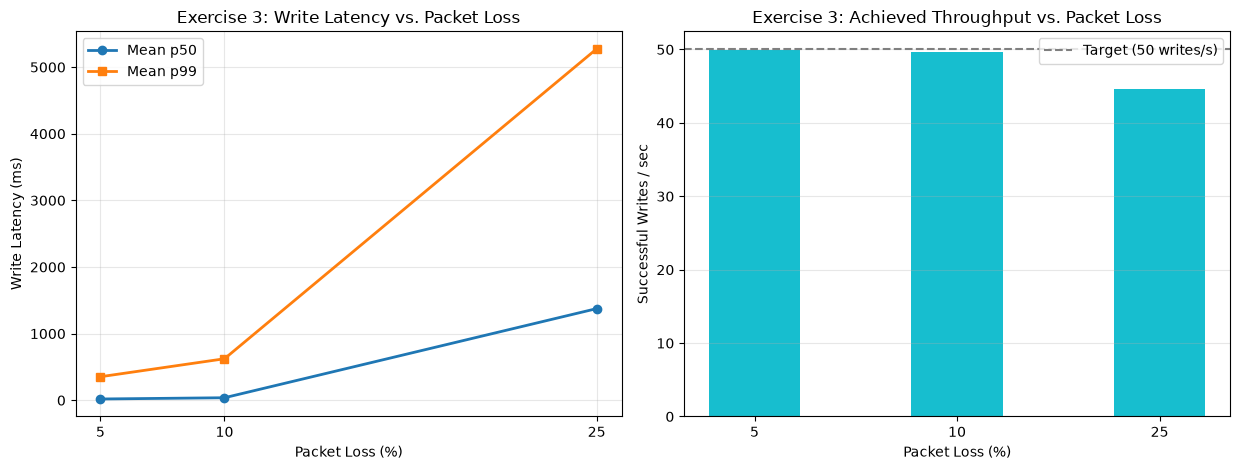

,run_id,loss_pct,trial,attempted,successful,failed,throughput_wps,p50_ms,p99_ms,elapsed_sec,errors
0,f5d78327,5,1,1000,1000,0,49.966518,20.849632,530.495469,20.013402,
1,f5d78327,5,2,1000,1000,0,49.981271,17.968822,228.484509,20.007494,
2,f5d78327,5,3,1000,1000,0,49.970117,18.187938,300.321000,20.011960,
3,f5d78327,10,1,1000,1000,0,49.612004,40.054064,626.097815,20.156412,
4,f5d78327,10,2,1000,1000,0,49.414578,32.522674,310.551392,20.236943,
5,f5d78327,10,3,1000,1000,0,49.913808,40.478740,931.928041,20.034536,
6,f5d78327,25,1,1000,1000,0,44.337222,1448.462861,5140.696021,22.554413,
7,f5d78327,25,2,1000,1000,0,45.770406,1231.902501,3514.604857,21.848178,
8,f5d78327,25,3,1000,1000,0,43.823819,1446.153233,7167.580387,22.818641,


In [29]:

run_exercise_3_sweep()

In [ ]:
! sudo docker compose -f expanded-docker-compose.yml down

### Exercise 3 — Analysis

Increasing packet loss noticeably degraded write latency and slightly reduced sustained write throughput, even though all attempted writes completed without timeouts in this sweep. Across the `5%`, `10%`, and `25%` loss tiers, mean `p50` latency rose from `17.12 ms` to `31.71 ms` and `516.70 ms`, while mean `p99` latency climbed from `372.07 ms` to `590.67 ms` and `2423.20 ms`. Mean achieved throughput edged down from `49.86` writes/s at `5%` loss to `49.35` writes/s at `10%` and `48.03` writes/s at `25%` against a `50` writes/s target.

The gap between `p50` and `p99` widens sharply at higher packet loss because packet drops do not impact every request equally. Median (`p50`) requests reflect typical completion times, whereas tail (`p99`) requests capture outliers hit by TCP retransmissions, repeated packet loss on individual frames, or extra round-trips waiting for Raft log replication to reach a majority quorum.

Because latency percentiles are computed over completed writes only—with failed or timed-out requests tracked separately—high-loss runs can also experience survivor bias when timeouts occur (as seen in earlier runs under heavier packet loss), meaning `p99` on completed requests alone can understate worst-case degradation. Overall, Consul's Raft consensus maintains availability and majority write progress under moderate-to-high packet loss, while tail latency grows substantially and throughput softens.